# Logistic Regression Feature Importance

This notebook separately explains Baseline A and Baseline B, the repository's saved logistic-regression models for the `adverse_365` outcome, then compares their feature importance. It reports signed model coefficients and uses SHAP's `LinearExplainer` to summarize which features most influence predicted adverse-outcome risk.

## Setup and interpretation

- Install SHAP in the active notebook environment if needed: `pip install shap`.
- Run from the repository root or the `notebooks/` directory. The fitted pipeline and its metadata are loaded from `models/`; the input data comes from `processed_output/`.
- The saved pipeline includes its fitted scaler. Use the already-processed feature CSV in metadata order; **do not scale the inputs separately before passing them to the pipeline**. For SHAP and coefficient interpretation below, the pipeline's scaler is applied once and the underlying logistic-regression estimator is explained.
- The artifact is a pickle and must only be loaded if it comes from a trusted source. Use package versions compatible with those recorded in the model metadata.
- Positive coefficients and SHAP values indicate higher model output for class 1 (`adverse_365`); negative values indicate lower output. These are associations learned by the model, not causal effects or evidence of fairness.
- Baseline A excludes demographic features; Baseline B includes them. Both analyses use the same held-out records and SHAP background sample.

In [5]:
from pathlib import Path
import json
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "processed_output" / "X_processed.csv").exists()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Run this notebook from the repository root or notebooks/; "
        "expected processed_output/X_processed.csv."
    )

BASELINES = ("A", "B")
BACKGROUND_SIZE = 200
EXPLANATION_SIZE = 1000
RANDOM_STATE = 42

model_dir = ROOT / "models"
metadata_by_baseline = {}
for baseline in BASELINES:
    metadata_path = model_dir / f"logistic_regression_baseline_{baseline.lower()}_metadata.json"
    model_path = model_dir / f"logistic_regression_baseline_{baseline.lower()}_best.pkl"
    if not metadata_path.exists() or not model_path.exists():
        raise FileNotFoundError(f"Missing model or metadata for Baseline {baseline}.")
    with metadata_path.open(encoding="utf-8") as handle:
        metadata_by_baseline[baseline] = json.load(handle)

metadata_a = metadata_by_baseline["A"]
metadata_b = metadata_by_baseline["B"]
if any(metadata_a[key] != metadata_b[key] for key in ("target", "test_size", "random_state")):
    raise ValueError("Baselines do not share the expected target and held-out split settings.")
print("Prepared both saved logistic-regression baselines for comparison.")

Prepared both saved logistic-regression baselines for comparison.


## Load processed data and reproduce the held-out split

Both models use the same held-out split and the same sampled training records as the SHAP background, making their explanations easier to compare. A bounded sample of held-out records is explained. No patient-level predictions or records are written to disk.

In [6]:
data_dir = ROOT / "processed_output"
X_processed = pd.read_csv(data_dir / "X_processed.csv", index_col=0)
y_frame = pd.read_csv(data_dir / "y_processed.csv", index_col=0)
feature_names_by_baseline = {
    baseline: metadata_by_baseline[baseline]["feature_columns"]
    for baseline in BASELINES
}
all_feature_names = sorted(set().union(*map(set, feature_names_by_baseline.values())))
target_name = metadata_a["target"]

if y_frame.shape[1] != 1 or not X_processed.index.equals(y_frame.index):
    raise ValueError("Expected one target column with rows aligned to the features.")
if target_name not in y_frame.columns:
    raise ValueError(f"Target {target_name!r} is missing from y_processed.csv.")
if not set(all_feature_names).issubset(X_processed.columns):
    missing_features = sorted(set(all_feature_names) - set(X_processed.columns))
    raise ValueError(f"Model input features are missing from the CSV: {missing_features}")

X = X_processed.loc[:, all_feature_names]
y = y_frame[target_name]
if y.isna().any() or set(y.unique()) != {0, 1}:
    raise ValueError("Expected a complete binary target encoded as 0 and 1.")
if not np.isfinite(X.to_numpy()).all():
    raise ValueError("Processed model features contain missing or infinite values.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=metadata_a["test_size"],
    random_state=metadata_a["random_state"],
    stratify=y,
)
print(f"Training rows: {len(X_train):,}; held-out rows: {len(X_test):,}")
print(f"Baseline A features: {len(feature_names_by_baseline['A'])}")
print(f"Baseline B features: {len(feature_names_by_baseline['B'])}")
print(f"Same split for both models: {len(X_test):,} held-out rows")

Training rows: 351,909; held-out rows: 87,978
Baseline A features: 30
Baseline B features: 51
Same split for both models: 87,978 held-out rows


## Analyze both models

Each model is analyzed independently using its saved pipeline. Because each pipeline standardizes its inputs, coefficients are per one standard deviation (after that model's scaler). The odds ratio is `exp(coefficient)`. SHAP explains the binary logistic model in log-odds space using the same sampled records for both background and held-out explanation data.

In [7]:
def explain_baseline(baseline):
    feature_names = feature_names_by_baseline[baseline]
    artifact_prefix = f"logistic_regression_baseline_{baseline.lower()}"
    model_path = model_dir / f"{artifact_prefix}_best.pkl"
    with model_path.open("rb") as handle:
        pipeline = pickle.load(handle)

    scalers = [step for step in pipeline.named_steps.values() if isinstance(step, StandardScaler)]
    classifiers = [step for step in pipeline.named_steps.values() if isinstance(step, LogisticRegression)]
    if len(scalers) != 1 or len(classifiers) != 1:
        raise TypeError(f"Baseline {baseline} must contain one StandardScaler and one LogisticRegression.")
    scaler, logistic_model = scalers[0], classifiers[0]
    if list(logistic_model.classes_) != [0, 1]:
        raise ValueError(f"Baseline {baseline} classes must be [0, 1].")
    if logistic_model.coef_.shape != (1, len(feature_names)):
        raise ValueError(f"Baseline {baseline} coefficient dimensions do not match its features.")

    coefficients = logistic_model.coef_.ravel()
    coefficient_table = pd.DataFrame({
        "feature": feature_names,
        "standardized_coefficient": coefficients,
        "odds_ratio_per_1_sd": np.exp(coefficients),
    })
    coefficient_table["absolute_coefficient"] = coefficient_table["standardized_coefficient"].abs()
    coefficient_table = coefficient_table.sort_values(
        "absolute_coefficient", ascending=False
    ).drop(columns="absolute_coefficient").reset_index(drop=True)

    X_background = X_train.loc[:, feature_names].sample(
        n=min(BACKGROUND_SIZE, len(X_train)), random_state=RANDOM_STATE
    )
    X_explain = X_test.loc[:, feature_names].sample(
        n=min(EXPLANATION_SIZE, len(X_test)), random_state=RANDOM_STATE
    )
    background_scaled = scaler.transform(X_background)
    explain_scaled = scaler.transform(X_explain)
    explainer = shap.LinearExplainer(logistic_model, background_scaled)
    shap_result = explainer.shap_values(explain_scaled)
    if isinstance(shap_result, list):
        shap_values = np.asarray(shap_result[1] if len(shap_result) > 1 else shap_result[0])
    else:
        shap_values = np.asarray(shap_result)
    if shap_values.ndim == 3:
        if shap_values.shape[2] == 2:
            shap_values = shap_values[:, :, 1]
        elif shap_values.shape[2] == 1:
            shap_values = shap_values[:, :, 0]
        else:
            raise ValueError(f"Unexpected SHAP output shape for Baseline {baseline}: {shap_values.shape}")
    if shap_values.shape != explain_scaled.shape:
        raise ValueError(f"Unexpected SHAP shape for Baseline {baseline}: {shap_values.shape}")

    shap_importance = pd.DataFrame({
        "feature": feature_names,
        "mean_absolute_shap_value": np.abs(shap_values).mean(axis=0),
        "mean_shap_value": shap_values.mean(axis=0),
    }).sort_values("mean_absolute_shap_value", ascending=False).reset_index(drop=True)
    return {
        "feature_names": feature_names,
        "coefficients": coefficients,
        "coefficient_table": coefficient_table,
        "shap_values": shap_values,
        "explain_scaled": explain_scaled,
        "shap_importance": shap_importance,
    }

results = {baseline: explain_baseline(baseline) for baseline in BASELINES}
for baseline in BASELINES:
    print(f"\nBaseline {baseline}: sorted signed coefficients and odds ratios")
    display(results[baseline]["coefficient_table"])


Baseline A: sorted signed coefficients and odds ratios


,feature,standardized_coefficient,odds_ratio_per_1_sd
0,INIT_AGE,-0.349182,0.705265
1,FUNC_STATUS_PERCENT_MAPPED,-0.336040,0.714595
2,A2A2B_STATUS_eligible,-0.088142,0.915631
3,dialysis_at_listing,0.065664,1.067868
4,BMI_TCR_MISSING,0.050428,1.051721
5,FUNC_STATUS_SCALE_unknown,0.049497,1.050743
6,FUNC_STATUS_SCALE_pediatric_lansky,-0.047822,0.953304
7,dialysis_years_at_listing,0.041926,1.042817
8,BMI_TCR_CLEAN,-0.041297,0.959544
9,INIT_STAT_4010,-0.033276,0.967272



Baseline B: sorted signed coefficients and odds ratios


,feature,standardized_coefficient,odds_ratio_per_1_sd
0,INIT_AGE,-0.330668,0.718444
1,FUNC_STATUS_PERCENT_MAPPED,-0.326492,0.721450
2,A2A2B_STATUS_eligible,-0.081754,0.921498
3,REGION_4,0.074749,1.077613
4,dialysis_at_listing,0.067518,1.069849
5,ETHCAT_1,0.065200,1.067373
6,dialysis_years_at_listing,0.055533,1.057103
7,FUNC_STATUS_SCALE_pediatric_lansky,-0.049881,0.951343
8,FUNC_STATUS_SCALE_unknown,0.049733,1.050991
9,BMI_TCR_MISSING,0.048999,1.050219


## Top 10 SHAP features for each model

Mean absolute SHAP values rank overall influence, while signed SHAP values show whether features typically push model scores toward or away from adverse outcome. Each model gets its own table, bar chart and beeswarm plot.

In [8]:
for baseline in BASELINES:
    baseline_result = results[baseline]
    feature_names = baseline_result["feature_names"]
    shap_importance = baseline_result["shap_importance"]
    top_10_shap = shap_importance.head(10)
    print(f"\nBaseline {baseline}: top 10 mean absolute SHAP features")
    display(top_10_shap)



Baseline A: top 10 mean absolute SHAP features


,feature,mean_absolute_shap_value,mean_shap_value
0,INIT_AGE,0.271483,0.038497
1,FUNC_STATUS_PERCENT_MAPPED,0.256017,-0.015261
2,dialysis_at_listing,0.062773,0.002340
3,dialysis_years_at_listing,0.036632,0.000127
4,BMI_TCR_CLEAN,0.034012,-0.008419
5,INIT_STAT_4010,0.029834,-0.004498
6,INIT_STAT_4099,0.029719,-0.004480
7,A2A2B_STATUS_eligible,0.024703,-0.001201
8,FUNC_STATUS_SCALE_pediatric_lansky,0.023783,0.012259
9,A2A2B_STATUS_unknown,0.020534,-0.005220



Baseline B: top 10 mean absolute SHAP features


,feature,mean_absolute_shap_value,mean_shap_value
0,INIT_AGE,0.257088,0.036456
1,FUNC_STATUS_PERCENT_MAPPED,0.248743,-0.014828
2,ETHCAT_1,0.065620,-0.005959
3,dialysis_at_listing,0.064545,0.002406
4,dialysis_years_at_listing,0.048521,0.000169
5,REGION_4,0.038146,0.004016
6,BMI_TCR_CLEAN,0.037836,-0.009366
7,INIT_STAT_4010,0.031566,-0.004759
8,INIT_STAT_4099,0.031465,-0.004744
9,ETHCAT_5,0.026639,0.002638


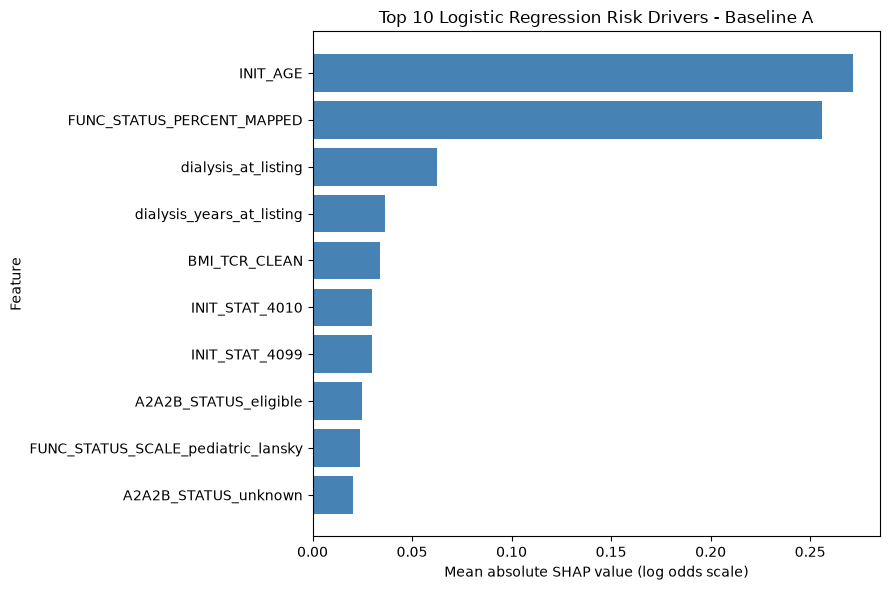

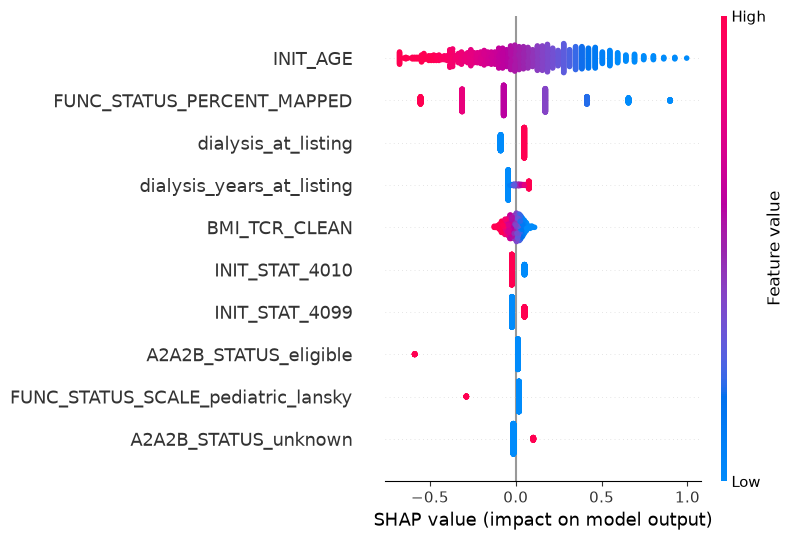

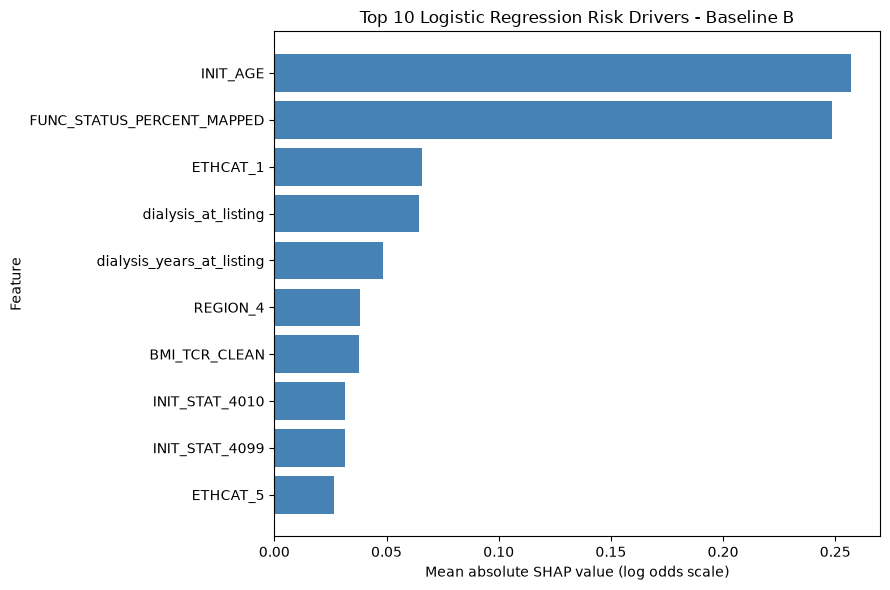

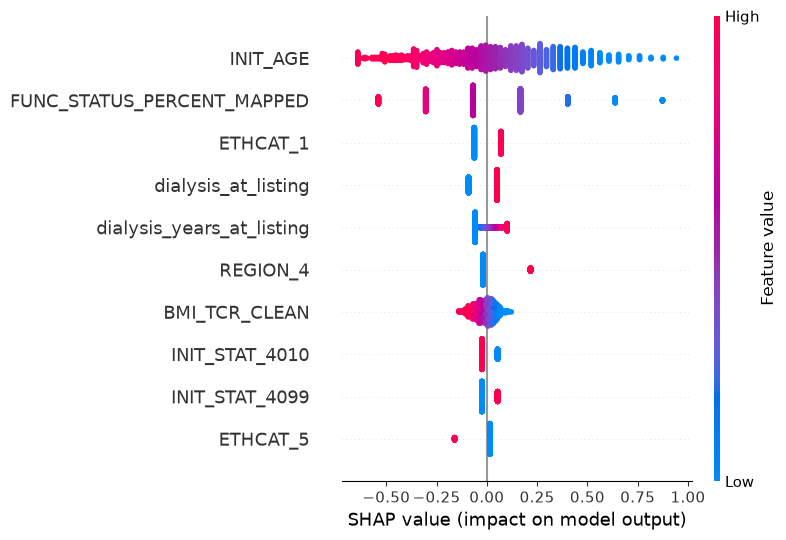

In [9]:
for baseline in BASELINES:
    baseline_result = results[baseline]
    feature_names = baseline_result["feature_names"]
    shap_values = baseline_result["shap_values"]
    explain_scaled = baseline_result["explain_scaled"]
    top_10_shap = baseline_result["shap_importance"].head(10)
    BASELINE = baseline
    fig, ax = plt.subplots(figsize=(9, 6))
    bar_data = top_10_shap.sort_values("mean_absolute_shap_value", ascending=True)
    ax.barh(bar_data["feature"], bar_data["mean_absolute_shap_value"], color="steelblue")
    ax.set_xlabel("Mean absolute SHAP value (log odds scale)")
    ax.set_ylabel("Feature")
    ax.set_title(f"Top 10 Logistic Regression Risk Drivers - Baseline {baseline}")
    fig.tight_layout()
    plt.show()
    shap.summary_plot(
        shap_values,
        explain_scaled,
        feature_names=feature_names,
        max_display=10,
        plot_type="dot",
    )


## Reading these results responsibly

The coefficient table gives the model's adjusted linear direction for each feature while holding its other inputs fixed; it is not a standalone clinical effect. SHAP rankings describe this model on the sampled held-out records and depend on the chosen background data. Correlated and one-hot encoded features can share or redistribute importance. Neither coefficients nor SHAP values establish causality, clinical validity, or fairness. Review model performance and validation limitations alongside these explanations.

## What the top risk factors mean

The summary below is generated from the selected baseline and the SHAP sample above. Importance tells you how strongly a feature influences model scores overall; the average signed SHAP value indicates whether that feature typically pushed scores toward or away from adverse outcome in this sample. The coefficient provides the model's direction as the standardized feature increases. For one-hot or missingness indicators, interpret an increase as the encoded indicator moving toward 1, not as a continuous clinical measurement. Feature names ending in `_MISSING` indicate a missing-value flag. Use the project's data dictionary to interpret coded categories; this is a description of model behavior, not medical advice or a causal claim.

In [10]:
for baseline in BASELINES:
    baseline_result = results[baseline]
    coefficients = baseline_result["coefficients"]
    feature_names = baseline_result["feature_names"]
    shap_importance = baseline_result["shap_importance"]
    shap_values = baseline_result["shap_values"]
    BASELINE = baseline
    signed_shap = shap_values.mean(axis=0)
    coefficient_by_feature = pd.Series(coefficients, index=feature_names)
    factor_explanations = shap_importance.copy()
    factor_explanations["mean_shap_value"] = signed_shap
    factor_explanations["standardized_coefficient"] = factor_explanations["feature"].map(
        coefficient_by_feature
    )
    factor_explanations["typical_sample_direction"] = np.where(
        factor_explanations["mean_shap_value"] > 0,
        "Usually pushes model score toward adverse outcome",
        np.where(
            factor_explanations["mean_shap_value"] < 0,
            "Usually pushes model score away from adverse outcome",
            "Little average directional contribution in this sample",
        ),
    )
    factor_explanations["coefficient_direction"] = np.where(
        factor_explanations["standardized_coefficient"] > 0,
        "Higher encoded feature value increases modeled odds",
        np.where(
            factor_explanations["standardized_coefficient"] < 0,
            "Higher encoded feature value decreases modeled odds",
            "No linear effect",
        ),
    )
    explanation_columns = [
        "feature",
        "mean_absolute_shap_value",
        "mean_shap_value",
        "typical_sample_direction",
        "coefficient_direction",
    ]
    print(
        f"Baseline {baseline}: the strongest overall feature influences "
        "in this held-out sample are listed below."
    )
    display(factor_explanations.head(10)[explanation_columns])


Baseline A: the strongest overall feature influences in this held-out sample are listed below.


,feature,mean_absolute_shap_value,mean_shap_value,typical_sample_direction,coefficient_direction
0,INIT_AGE,0.271483,3.849715e-02,Usually pushes model score toward adverse outcome,Higher encoded feature value decreases modeled...
1,FUNC_STATUS_PERCENT_MAPPED,0.256017,-8.419202e-03,Usually pushes model score away from adverse o...,Higher encoded feature value decreases modeled...
2,dialysis_at_listing,0.062773,2.340024e-03,Usually pushes model score toward adverse outcome,Higher encoded feature value increases modeled...
3,dialysis_years_at_listing,0.036632,1.274669e-04,Usually pushes model score toward adverse outcome,Higher encoded feature value increases modeled...
4,BMI_TCR_CLEAN,0.034012,-4.134019e-03,Usually pushes model score away from adverse o...,Higher encoded feature value decreases modeled...
5,INIT_STAT_4010,0.029834,-1.638107e-03,Usually pushes model score away from adverse o...,Higher encoded feature value decreases modeled...
6,INIT_STAT_4099,0.029719,-8.121651e-05,Usually pushes model score away from adverse o...,Higher encoded feature value increases modeled...
7,A2A2B_STATUS_eligible,0.024703,1.050209e-04,Usually pushes model score toward adverse outcome,Higher encoded feature value decreases modeled...
8,FUNC_STATUS_SCALE_pediatric_lansky,0.023783,6.517302e-03,Usually pushes model score toward adverse outcome,Higher encoded feature value decreases modeled...
9,A2A2B_STATUS_unknown,0.020534,-1.631475e-19,Usually pushes model score away from adverse o...,Higher encoded feature value increases modeled...


Baseline B: the strongest overall feature influences in this held-out sample are listed below.


,feature,mean_absolute_shap_value,mean_shap_value,typical_sample_direction,coefficient_direction
0,INIT_AGE,0.257088,3.645597e-02,Usually pushes model score toward adverse outcome,Higher encoded feature value decreases modeled...
1,FUNC_STATUS_PERCENT_MAPPED,0.248743,-9.365784e-03,Usually pushes model score away from adverse o...,Higher encoded feature value decreases modeled...
2,ETHCAT_1,0.065620,2.406088e-03,Usually pushes model score toward adverse outcome,Higher encoded feature value increases modeled...
3,dialysis_at_listing,0.064545,1.688339e-04,Usually pushes model score toward adverse outcome,Higher encoded feature value increases modeled...
4,dialysis_years_at_listing,0.048521,-4.016847e-03,Usually pushes model score away from adverse o...,Higher encoded feature value increases modeled...
5,REGION_4,0.038146,-1.333872e-03,Usually pushes model score away from adverse o...,Higher encoded feature value increases modeled...
6,BMI_TCR_CLEAN,0.037836,-4.745017e-05,Usually pushes model score away from adverse o...,Higher encoded feature value decreases modeled...
7,INIT_STAT_4010,0.031566,-8.296965e-05,Usually pushes model score away from adverse o...,Higher encoded feature value decreases modeled...
8,INIT_STAT_4099,0.031465,6.901622e-03,Usually pushes model score toward adverse outcome,Higher encoded feature value increases modeled...
9,ETHCAT_5,0.026639,-1.558307e-19,Usually pushes model score away from adverse o...,Higher encoded feature value decreases modeled...
